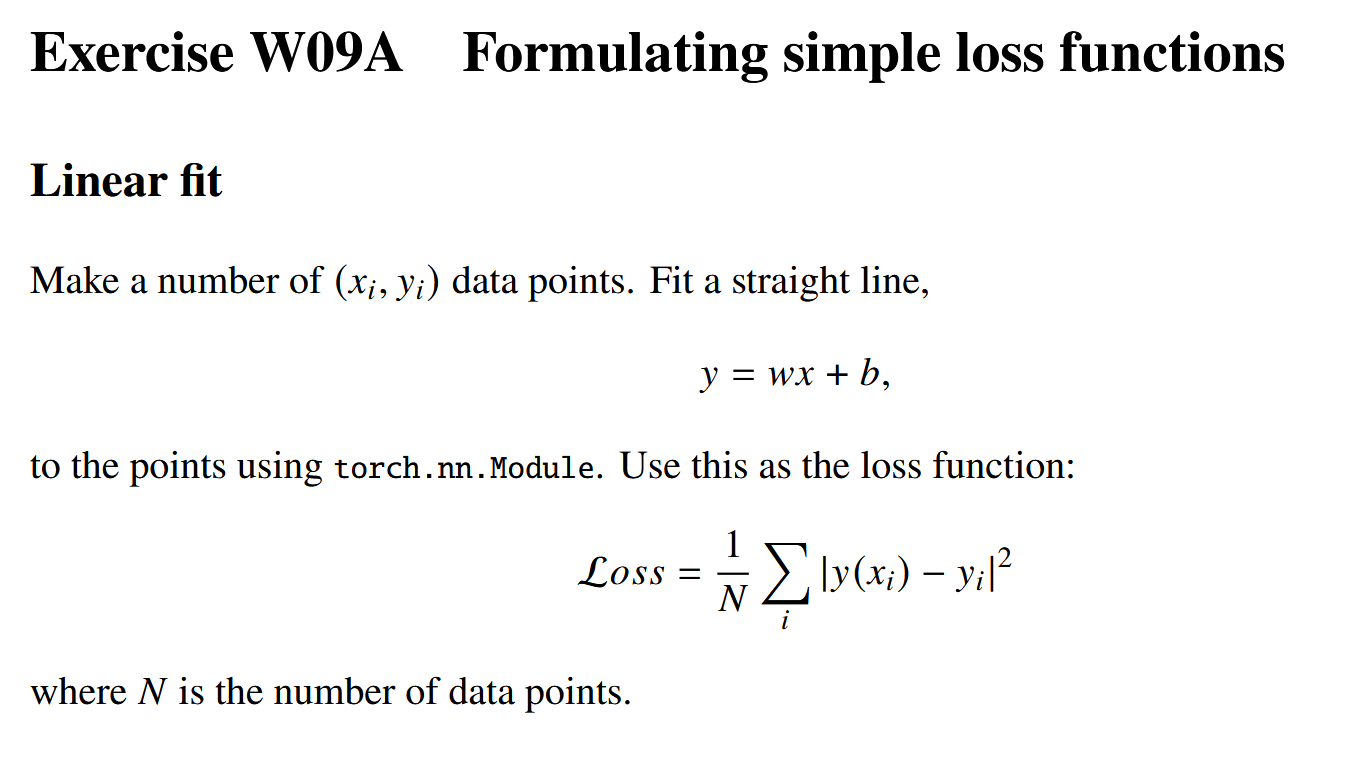

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim

N = 20
x = torch.randn(N, 1)

y_true = 3.0 * x + 2.0 + 0.1 * torch.randn(N, 1) # add noise

class Line(nn.Module):
    def __init__(self, w=0, b=1):
        super().__init__()
        self.w = nn.Parameter(torch.tensor(float(w)))
        self.b = nn.Parameter(torch.tensor(float(b)))

    def forward(self, x):
        y = self.w * x + self.b
        return y

def Loss(pred, target):
    return torch.mean(torch.abs(pred - target)**2)

line = Line()

optimizer = optim.Adam(line.parameters(), lr=0.05)

epochs = 1000

for e in range(epochs):
    optimizer.zero_grad()

    y_model = line(x)
    loss = Loss(y_model, y_true)
    loss.backward()

    optimizer.step()

    if (e+1) % 100 == 0:
        print(f'Epoch {e+1}, Loss = {loss.item()}')

Epoch 100, Loss = 0.013825726695358753
Epoch 200, Loss = 0.006382911000400782
Epoch 300, Loss = 0.00638289749622345
Epoch 400, Loss = 0.006382887717336416
Epoch 500, Loss = 0.006382890045642853
Epoch 600, Loss = 0.006382890045642853
Epoch 700, Loss = 0.006382890045642853
Epoch 800, Loss = 0.006382890045642853
Epoch 900, Loss = 0.006382890045642853
Epoch 1000, Loss = 0.006382890045642853


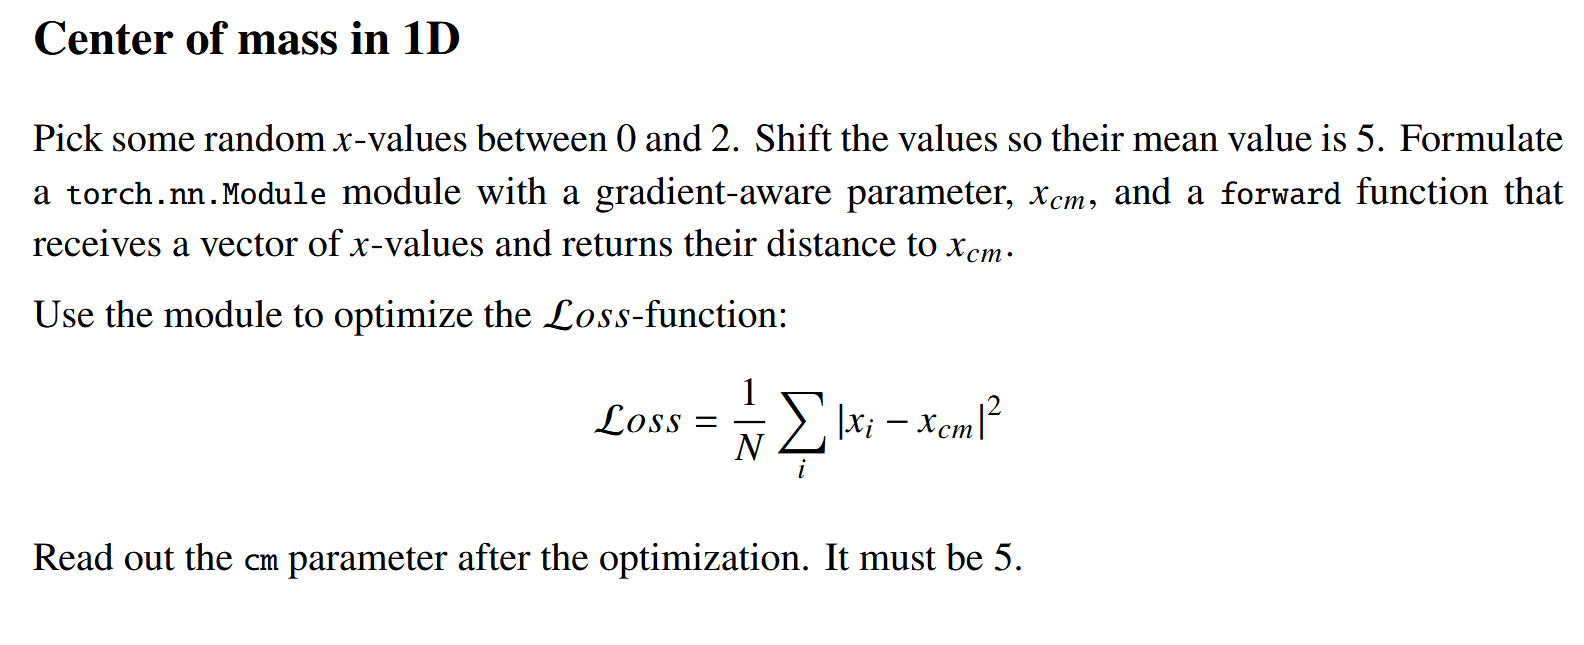

In [12]:
x = torch.rand(N) * 2.0
x = x - torch.mean(x) + 5.0

class CenterOfMass(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.x_cm = nn.Parameter(torch.tensor(0.0))

    def forward(self, x):
        return x - self.x_cm

model = CenterOfMass()

def Loss(dist):
    return torch.mean(torch.abs(dist)**2)

optimizer = optim.Adam(model.parameters(), lr=0.05)

epochs = 1000

for e in range(epochs):
    optimizer.zero_grad()

    distance = model(x)
    loss = Loss(distance)
    loss.backward()

    optimizer.step()

    # if (e+1) % 100 == 0:
    #     print(f'Epoch {e+1}, Loss = {loss.item()}')

print(f'Final prediction: {model.x_cm.item()}')


Final prediction: 5.000003337860107


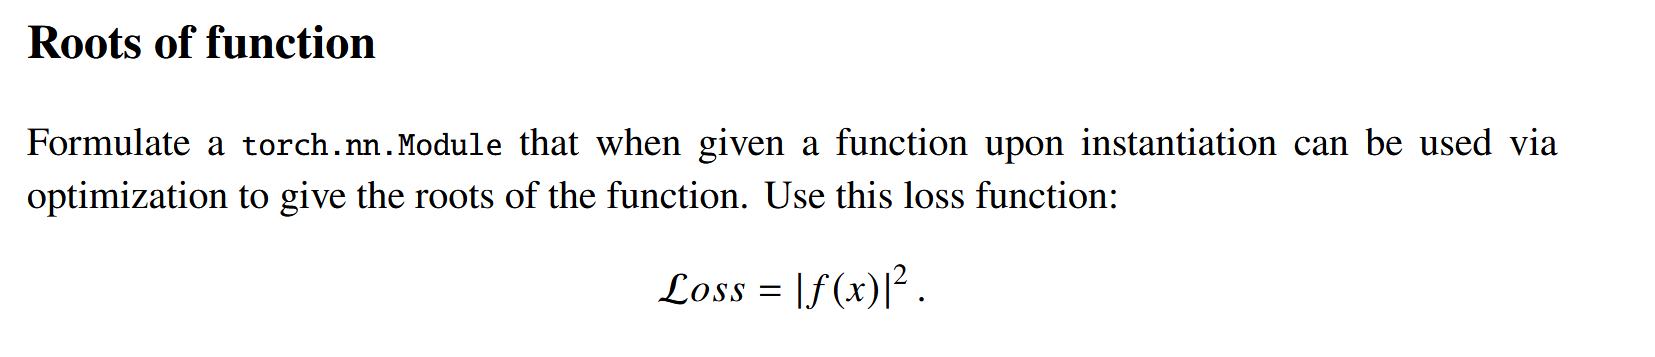

In [18]:
class RootFinder(nn.Module):
    def __init__(self, *args, function, initial_guess=0.0, **kwargs):
        super().__init__(*args, **kwargs)
        self.f = function
        self.x = nn.Parameter(torch.tensor([float(initial_guess)]))

    def forward(self):
        return self.f(self.x)

# Define a target function
def my_function(x):
    return x**2 - 4.0

model = RootFinder(function=my_function, initial_guess=5.0)

optimizer = optim.SGD(model.parameters(), lr=0.01)

epochs = 300
for epoch in range(epochs):
    optimizer.zero_grad()
    
    fx = model()
    
    loss = torch.abs(fx)**2 
    
    loss.backward()
    optimizer.step()

print(f"Final evaluated root: {model.x.item():.4f}")
print(f"Function value at root (should be ~0): {my_function(model.x).item():.4f}")

Final evaluated root: 2.0000
Function value at root (should be ~0): -0.0000
